# **12 - Calibrated prediction intervals for the chosen models**

This notebook answers the review finding F-09: the only contract-level interval of the project belonged to a model that is not the chosen one and under-covered, and the chosen models had none.

**Method (split conformal prediction on the `log1p` scale).**
1. In every fit window the last 6 months are the **calibration window** and the rows before them are the proper training rows (a time-ordered split).
2. The chosen model is fit on the proper rows only and predicts the calibration rows (a backtest). The nonconformity score is the absolute residual on the `log1p` scale.
3. The radius for a nominal level is the finite-sample quantile of the scores: the `ceil((n + 1) * level)`-th smallest of `n` scores.
4. The interval of a contract is `[expm1(z - q), expm1(z + q)]` around `z = log1p(prediction)` (clipped at zero), where the prediction comes from the model refit on the whole fit window.
5. **Scaled version:** each score is divided by a difficulty estimate, the standard deviation of `log1p(target)` of the building type in the proper rows (fit window only), and the interval radius is `q * sigma(building type)`.

**Evaluation.** Coverage and mean width are measured on the two pseudo-test years (fit before 2023 and before 2024) and on 2025 (fit before 2025), overall and by building type and by predicted-price tercile. The settings of the chosen models are those tuned in notebook 11 (identical in every window). Nominal levels are 80% and 95%.

**Assumption and limitation.** Split conformal coverage is guaranteed only if the calibration rows and the evaluation rows are exchangeable. A calibration window at the end of the fit window and an evaluation year that follows it are not exchangeable if the market level or the error scale shifts; the notebook measures this instead of assuming it. 2025 was inspected in earlier iterations of this project (see the README).

In [1]:
import sys
import time
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'src' / 'rent_model').exists())
sys.path.insert(0, str(ROOT / 'src'))

import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from rent_model import config
from rent_model.conformal import CALIBRATION_MONTHS, LEVELS, calibrate, coverage, coverage_by_group, intervals
from rent_model.data import load_clean
from rent_model.diagnostics import price_tier
from rent_model.features import build_features, select_track
from rent_model.io import save_run
from rent_model.pseudotest import WINDOWS, check_windows, window_split
from rent_model.recipes import ModelRecipe
from rent_model.splits import temporal_split

pd.set_option('display.float_format', '{:,.4f}'.format)
pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 30)
plt.rcParams['figure.dpi'] = 100
config.FIGURES_DIR.mkdir(parents=True, exist_ok=True)
print('Random seed:', config.RANDOM_SEED, '| calibration window (months):', CALIBRATION_MONTHS, '| levels:', LEVELS)

Random seed: 42 | calibration window (months): 6 | levels: (0.8, 0.95)


## Data, chosen models and settings

In [2]:
df = load_clean()
check_windows()
# chosen model of each track = the extrapolating model selected on the pseudo-tests by notebook 11 (the same model the leaderboard of notebook 09 marks as chosen)
chosen = {t: json.loads((config.METRICS_DIR / f'pseudotest_v2_{t}.json').read_text(encoding='utf-8'))['selection']['extrapolating'] for t in config.TRACKS}
# Settings tuned by notebook 11 (RandomizedSearchCV inside each fit window); the search selected the same values in all windows of both tracks.
PARAMS = dict(learning_rate=0.05, max_iter=300, max_leaf_nodes=255, min_samples_leaf=20, l2_regularization=0.0, min_frequency=30)
data = {}
for track, spec in config.TRACKS.items():
    d = select_track(df, track)
    train, test = temporal_split(d)
    data[track] = dict(df=d, train=train, test=test, target=spec['target'])
    saved = json.loads((config.METRICS_DIR / f'{track}__{chosen[track]}.json').read_text(encoding='utf-8'))[-1]['meta']['params']
    assert saved == PARAMS, 'the settings differ from the run saved by notebook 11'
    print(f"{track}: chosen model {chosen[track]} | rows: {len(d):,} | TRAIN {len(train):,} | TEST 2025 {len(test):,}")
print('settings:', PARAMS, '(equal to the settings saved with the final run of each chosen model)')

jeonse: chosen model hgb_detrended_ld_median_recal | rows: 176,783 | TRAIN 138,848 | TEST 2025 37,935
wolse: chosen model hgb_detrended_ld_median | rows: 210,543 | TRAIN 152,714 | TEST 2025 57,829
settings: {'learning_rate': 0.05, 'max_iter': 300, 'max_leaf_nodes': 255, 'min_samples_leaf': 20, 'l2_regularization': 0.0, 'min_frequency': 30} (equal to the settings saved with the final run of each chosen model)


## 1) Calibration in each fit window

In [3]:
SETUPS = [('pseudo-test 2023', WINDOWS[0]['fit_end'], 2023), ('pseudo-test 2024', WINDOWS[1]['fit_end'], 2024), ('2025', config.TEST_START, 2025)]
R, rows = {}, []
for track in config.TRACKS:
    d = data[track]['df']
    for name, fit_end, year in SETUPS:
        t0 = time.time()
        fit = d[d['contract_date'] < fit_end]
        ev = d[(d['contract_date'] >= fit_end) & (d['contract_date'].dt.year == year)]
        factory = lambda: ModelRecipe(chosen[track], track, params=PARAMS)
        cal = calibrate(factory, fit, track)
        assert pd.Timestamp(cal.last) < fit_end and fit['contract_date'].max() < ev['contract_date'].min()      # calibration rows precede the evaluation rows
        model = factory().fit(fit, fit_end)
        pred = model.predict(build_features(ev, track, include_time=True, include_legal_dong=True), ev['contract_month'])
        R[(track, name)] = dict(cal=cal, y=ev[data[track]['target']].to_numpy(), pred=np.asarray(pred), bt=ev['building_type'].to_numpy(),
                                months=ev['contract_month'].to_numpy(), quarter=('Q' + ev['contract_date'].dt.quarter.astype(str)).to_numpy())
        rows.append({'track': track, 'evaluation': name, 'fit rows': len(fit), 'calibration window': f'{cal.start} to {cal.last}', 'calibration rows': cal.n,
                     'q80 (log)': cal.q[0.8], 'q95 (log)': cal.q[0.95], 'q80 scaled': cal.q_scaled[0.8], 'q95 scaled': cal.q_scaled[0.95],
                     'median |residual|': cal.median_abs_residual, 'mean residual': cal.mean_residual})
        print(f'{track} / {name}: calibrated and evaluated in {time.time() - t0:,.0f} s')
display(pd.DataFrame(rows).set_index(['track', 'evaluation']))
# the 2025 predictions are those saved by notebook 11 for the chosen model
for track in config.TRACKS:
    saved = pd.read_parquet(config.PREDICTIONS_DIR / f'{track}__{chosen[track]}.parquet')['y_pred'].to_numpy()
    assert np.allclose(saved, R[(track, '2025')]['pred']), 'the 2025 predictions differ from the saved run'
print('assertion passed: the calibration window ends before the fit end in every case and the 2025 predictions equal the saved run')

jeonse / pseudo-test 2023: calibrated and evaluated in 43 s


jeonse / pseudo-test 2024: calibrated and evaluated in 51 s


jeonse / 2025: calibrated and evaluated in 67 s


wolse / pseudo-test 2023: calibrated and evaluated in 20 s


wolse / pseudo-test 2024: calibrated and evaluated in 31 s


wolse / 2025: calibrated and evaluated in 34 s


fit rows        calibration window  calibration rows  q80 (log)  q95 (log)  q80 scaled  q95 scaled  median |residual|  mean residual
track  evaluation                                                                                                                                            
jeonse pseudo-test 2023     50327  2022-07-01 to 2022-12-01             22428     0.2937     0.5831      0.5486      1.0641             0.1351        -0.0914
       pseudo-test 2024     97840  2023-07-01 to 2023-12-01             23118     0.2611     0.4878      0.4870      0.9268             0.1283         0.0262
       2025                138848  2024-07-01 to 2024-12-01             19330     0.2429     0.5460      0.4708      1.0523             0.1069        -0.0753
wolse  pseudo-test 2023     50860  2022-07-01 to 2022-12-01             23342     0.6584     1.3701      0.8973      1.8739             0.2749        -0.0269
       pseudo-test 2024    102182  2023-07-01 to 2023-12-01             24790     0.6479     1.5549      0.8297      2.0768             0.2297        -0.1540
       2025                152714  2024-07-01 to 2024-12-01             26616     0.7461     1.6671      0.9754      2.2429             0.2744        -0.1898

assertion passed: the calibration window ends before the fit end in every case and the 2025 predictions equal the saved run


**Interpretation.** In every fit window the calibration rows are the last 6 months (for the 2025 evaluation: 2024-07-01 to 2024-12-01, 19,330 Jeonse rows and 26,616 Wolse rows), and the assertion confirms that they end before the fit end and that no evaluation row is among them; the 2025 predictions equal the run saved by notebook 11. The radius on the `log1p` scale of the 80% interval is 0.2429 (Jeonse) and 0.7461 (Wolse) for the 2025 evaluation, and 0.5460 and 1.6671 for the 95% interval: the Wolse radius is about three times the Jeonse radius, which reflects the larger dispersion of the monthly rent around the model (median absolute residual 0.2744 against 0.1069). In the first pseudo-test window the calibration backtest model is trained only on the rows before the calibration window, so the first window is the weakest calibration. The signed mean residual of the calibration window is negative in most windows (for example -0.0753 in Jeonse and -0.1898 in Wolse for 2025), i.e. the backtest model overpredicts the calibration months.

## 2) Coverage and width, overall

In [4]:
def arrays(track, names):
    keys = [(track, n) for n in names]
    cat = lambda k: np.concatenate([R[key][k] for key in keys])
    pred = cat('pred')
    iv = {}
    for scaled in (False, True):
        parts = [intervals(R[key]['pred'], R[key]['cal'], R[key]['bt'], scaled) for key in keys]
        iv[scaled] = {lv: (np.concatenate([p[lv][0] for p in parts]), np.concatenate([p[lv][1] for p in parts])) for lv in LEVELS}
    tiers = np.concatenate([price_tier(R[key]['pred']).to_numpy() for key in keys])
    return dict(y=cat('y'), pred=pred, bt=cat('bt'), quarter=cat('quarter'), tier=tiers, iv=iv)

EVALS = {'pseudo-tests 2023+2024': ['pseudo-test 2023', 'pseudo-test 2024'], 'pseudo-test 2023': ['pseudo-test 2023'],
         'pseudo-test 2024': ['pseudo-test 2024'], '2025': ['2025']}
A = {(t, label): arrays(t, names) for t in config.TRACKS for label, names in EVALS.items()}

rows = []
for (track, label), a in A.items():
    for scaled in (False, True):
        for lv in LEVELS:
            lo, hi = a['iv'][scaled][lv]
            cov, width = coverage(a['y'], lo, hi)
            rows.append({'track': track, 'evaluation': label, 'version': 'scaled' if scaled else 'unscaled', 'nominal': lv, 'coverage': cov,
                         'mean width (10,000 KRW)': width, 'median relative width': float(np.median((hi - lo) / a['pred']))})
overall = pd.DataFrame(rows).set_index(['track', 'evaluation', 'version', 'nominal'])
display(overall)

coverage  mean width (10,000 KRW)  median relative width
track  evaluation             version  nominal                                                          
jeonse pseudo-tests 2023+2024 unscaled 0.8000     0.8344              21,964.9104                 0.5960
                                       0.9500     0.9566              43,978.3797                 1.2333
                              scaled   0.8000     0.8302              23,373.5512                 0.5953
                                       0.9500     0.9554              46,854.6118                 1.1758
       pseudo-test 2023       unscaled 0.8000     0.8416              22,410.1811                 0.5960
                                       0.9500     0.9681              46,376.6543                 1.2334
                              scaled   0.8000     0.8459              24,142.9930                 0.6841
                                       0.9500     0.9680              49,093.5809                 1.3964
       pseudo-test 2024       unscaled 0.8000     0.8261              21,449.0075                 0.5283
                                       0.9500     0.9434              41,199.6724                 1.0147
                              scaled   0.8000     0.8120              22,482.0546                 0.5953
                                       0.9500     0.9408              44,260.4804                 1.1758
       2025                   unscaled 0.8000     0.8127              22,345.3616                 0.4905
                                       0.9500     0.9584              52,255.2505                 1.1471
                              scaled   0.8000     0.8186              24,480.3914                 0.5659
                                       0.9500     0.9595              57,402.8188                 1.3312
wolse  pseudo-tests 2023+2024 unscaled 0.8000     0.7780                  99.1482                 1.4247
                                       0.9500     0.9344                 290.9024                 3.9424
                              scaled   0.8000     0.7794                 103.5029                 1.3949
                                       0.9500     0.9339                 339.9907                 3.8722
       pseudo-test 2023       unscaled 0.8000     0.8052                  97.4513                 1.4398
                                       0.9500     0.9410                 253.7358                 3.7488
                              scaled   0.8000     0.8150                 104.1791                 1.4635
                                       0.9500     0.9419                 293.0286                 3.8599
       pseudo-test 2024       unscaled 0.8000     0.7504                 100.8717                 1.4119
                                       0.9500     0.9277                 328.6501                 4.6002
                              scaled   0.8000     0.7432                 102.8161                 1.3929
                                       0.9500     0.9258                 387.6869                 4.8483
       2025                   unscaled 0.8000     0.8057                 113.4783                 1.6647
                                       0.9500     0.9530                 354.6022                 5.2020
                              scaled   0.8000     0.8095                 122.4568                 1.7508
                                       0.9500     0.9542                 449.0063                 5.9484

**Interpretation.** On 2025 the marginal coverage is close to nominal in both tracks: Jeonse 0.8127 (80% interval) and 0.9584 (95%) with the unscaled version and 0.8186 and 0.9595 with the scaled version; Wolse 0.8057 and 0.9530 unscaled and 0.8095 and 0.9542 scaled. On the pooled pseudo-tests Jeonse covers 0.8344 and 0.9566 (unscaled), but Wolse falls below nominal (0.7780 and 0.9344), mainly because of the 2024 window (0.7504 and 0.9277; the 2023 window has 0.8052 and 0.9410). The scaled version is wider with almost the same overall coverage (Jeonse 2025: mean width 24,480.3914 against 22,345.3616 in units of 10,000 KRW). The intervals are wide: the median relative width of the 80% interval is 0.4905 of the prediction in Jeonse (1.1471 for 95%) and 1.6647 in Wolse (5.2020 for 95%), i.e. a single Wolse contract is predicted only within a range larger than the predicted rent itself. This is consistent with the high WAPE of the Wolse model.

## 3) Coverage by building type and by predicted-price tercile

In [5]:
GROUPS = {'building type': 'bt', 'predicted-price tercile': 'tier'}
group_tables = {}
for track in config.TRACKS:
    for label in ('pseudo-tests 2023+2024', '2025'):
        a = A[(track, label)]
        parts = []
        for gname, key in GROUPS.items():
            for scaled in (False, True):
                for lv in LEVELS:
                    lo, hi = a['iv'][scaled][lv]
                    t = coverage_by_group(a[key], a['y'], lo, hi).reset_index().rename(columns={'g': 'group'})
                    t.insert(0, 'grouping', gname); t.insert(1, 'version', 'scaled' if scaled else 'unscaled'); t.insert(2, 'nominal', lv)
                    parts.append(t)
        group_tables[(track, label)] = pd.concat(parts)
for track in config.TRACKS:
    for label in ('pseudo-tests 2023+2024', '2025'):
        t = group_tables[(track, label)]
        wide = t[t['nominal'] == 0.8].pivot_table(index=['grouping', 'group'], columns='version', values=['coverage', 'mean_width'])
        wide.insert(0, 'n', t[(t['nominal'] == 0.8) & (t['version'] == 'scaled')].set_index(['grouping', 'group'])['n'])
        print(f'{track} / {label}: coverage and mean width of the 80% interval by group')
        display(wide)

jeonse / pseudo-tests 2023+2024: coverage and mean width of the 80% interval by group


n coverage           mean_width            
version                                                           scaled unscaled      scaled    unscaled
grouping                group                                                                            
building type           Apartment                         48125   0.8887   0.8570 34,684.3897 30,465.3910
                        Detached / Multi-household house  10102   0.6609   0.6327  8,900.5929  8,315.7063
                        Officetel                          8581   0.8738   0.9431  9,277.8453 12,795.0943
                        Row house / Villa (multi-unit)    21713   0.7620   0.8354 10,608.2479 13,098.5551
predicted-price tercile T1 low                            29507   0.7472   0.7742  8,165.7126  8,947.9024
                        T2 mid                            29506   0.8385   0.8497 17,614.3809 17,723.2384
                        T3 high                           29508   0.9049   0.8794 44,339.6543 39,222.8618

jeonse / 2025: coverage and mean width of the 80% interval by group


n coverage           mean_width            
version                                                           scaled unscaled      scaled    unscaled
grouping                group                                                                            
building type           Apartment                         22645   0.8839   0.8473 34,475.0481 29,883.9864
                        Detached / Multi-household house   3977   0.5582   0.5265  8,726.4985  8,013.3942
                        Officetel                          3369   0.8551   0.9240  9,386.0776 12,454.4800
                        Row house / Villa (multi-unit)     7944   0.7474   0.8100 10,278.0973 12,225.5801
predicted-price tercile T1 low                            12645   0.7144   0.7344  8,301.4540  8,826.0810
                        T2 mid                            12645   0.8400   0.8357 19,405.2208 18,356.3383
                        T3 high                           12645   0.9015   0.8680 45,734.4994 39,853.6655

wolse / pseudo-tests 2023+2024: coverage and mean width of the 80% interval by group


n coverage          mean_width         
version                                                           scaled unscaled     scaled unscaled
grouping                group                                                                        
building type           Apartment                         33219   0.8098   0.7146   185.5388 136.4836
                        Detached / Multi-household house  29836   0.8235   0.9032    46.4238  71.3354
                        Officetel                         16206   0.7622   0.8021    70.1063  97.6425
                        Row house / Villa (multi-unit)    22593   0.6886   0.6885    82.2169  82.0625
predicted-price tercile T1 low                            33951   0.7886   0.8022    49.4655  57.8647
                        T2 mid                            33951   0.7632   0.7838    73.5808  81.5409
                        T3 high                           33952   0.7864   0.7479   187.4599 158.0374

wolse / 2025: coverage and mean width of the 80% interval by group


n coverage          mean_width         
version                                                           scaled unscaled     scaled unscaled
grouping                group                                                                        
building type           Apartment                         17911   0.8635   0.7710   225.9346 161.8530
                        Detached / Multi-household house  17711   0.8403   0.9260    51.8605  82.6521
                        Officetel                         10300   0.7594   0.7717    97.3121 111.2110
                        Row house / Villa (multi-unit)    11907   0.7260   0.7081    93.5602  88.5245
predicted-price tercile T1 low                            19276   0.8159   0.8274    57.5132  65.5210
                        T2 mid                            19276   0.7932   0.8147    83.2907  91.3853
                        T3 high                           19277   0.8195   0.7749   226.5609 183.5249

**Interpretation.** Marginal coverage hides large differences between groups. On 2025 the 80% interval covers (scaled / unscaled) 0.8839 / 0.8473 for Jeonse apartments, 0.8551 / 0.9240 for officetels, 0.7474 / 0.8100 for row houses and only 0.5582 / 0.5265 for detached houses; by predicted-price tercile 0.7144 / 0.7344 (low), 0.8400 / 0.8357 (mid) and 0.9015 / 0.8680 (high). In Wolse the 2025 coverage is 0.8635 / 0.7710 for apartments, 0.8403 / 0.9260 for detached houses, 0.7594 / 0.7717 for officetels and 0.7260 / 0.7081 for row houses; by tercile 0.8159 / 0.8274, 0.7932 / 0.8147 and 0.8195 / 0.7749. The pseudo-tests show the same pattern (Jeonse detached houses 0.6609 / 0.6327). The scaled version corrects some groups (Wolse apartments, Jeonse detached houses slightly) and worsens others (Jeonse officetels and row houses), so neither version gives group-conditional coverage: a single radius cannot fit groups whose error scales differ.

## 4) Does coverage drop under the shift between the calibration window and the evaluation year?

In [6]:
rows = []
for track in config.TRACKS:
    for name in ('pseudo-test 2023', 'pseudo-test 2024', '2025'):
        r = R[(track, name)]
        resid = np.log1p(r['y']) - np.log1p(r['pred'])
        cal = r['cal']
        label = {'pseudo-test 2023': 'pseudo-test 2023', 'pseudo-test 2024': 'pseudo-test 2024', '2025': '2025'}[name]
        iv = intervals(r['pred'], cal, r['bt'], scaled=False)
        row = {'track': track, 'evaluation': label, 'calibration median |residual|': cal.median_abs_residual, 'evaluation median |residual|': float(np.median(np.abs(resid))),
               'calibration mean residual': cal.mean_residual, 'evaluation mean residual': float(resid.mean()),
               'q80 calibration': cal.q[0.8], 'empirical 80% quantile of evaluation |residual|': float(np.quantile(np.abs(resid), 0.8)),
               'q95 calibration': cal.q[0.95], 'empirical 95% quantile of evaluation |residual|': float(np.quantile(np.abs(resid), 0.95))}
        for lv in LEVELS:
            row[f'coverage {lv:.0%}'] = coverage(r['y'], *iv[lv])[0]
        for q in ('Q1', 'Q2', 'Q3', 'Q4'):
            mask = r['quarter'] == q
            row[f'coverage 80% {q}'] = coverage(r['y'][mask], iv[0.8][0][mask], iv[0.8][1][mask])[0]
        rows.append(row)
shift = pd.DataFrame(rows).set_index(['track', 'evaluation'])
display(shift.T)

track                                                     jeonse                                     wolse                         
evaluation                                      pseudo-test 2023 pseudo-test 2024    2025 pseudo-test 2023 pseudo-test 2024    2025
calibration median |residual|                             0.1351           0.1283  0.1069           0.2749           0.2297  0.2744
evaluation median |residual|                              0.1237           0.1102  0.1067           0.2375           0.2764  0.2884
calibration mean residual                                -0.0914           0.0262 -0.0753          -0.0269          -0.1540 -0.1898
evaluation mean residual                                 -0.0209          -0.0577 -0.0526          -0.1291          -0.2391 -0.1200
q80 calibration                                           0.2937           0.2611  0.2429           0.6584           0.6479  0.7461
empirical 80% quantile of evaluation |residual|           0.2583           0.2386  0.2321           0.6440           0.7964  0.7288
q95 calibration                                           0.5831           0.4878  0.5460           1.3701           1.5549  1.6671
empirical 95% quantile of evaluation |residual|           0.4847           0.5201  0.4958           1.4865           1.7564  1.6341
coverage 80%                                              0.8416           0.8261  0.8127           0.8052           0.7504  0.8057
coverage 95%                                              0.9681           0.9434  0.9584           0.9410           0.9277  0.9530
coverage 80% Q1                                           0.8310           0.8600  0.8172           0.8247           0.7525  0.8164
coverage 80% Q2                                           0.8345           0.8241  0.8039           0.8073           0.7435  0.8007
coverage 80% Q3                                           0.8469           0.8082  0.8214           0.7975           0.7633  0.8087
coverage 80% Q4                                           0.8551           0.8067  0.8079           0.7890           0.7424  0.7943

**Interpretation.** Coverage does not drop on 2025: 0.8127 (Jeonse) and 0.8057 (Wolse) at the 80% level and 0.9584 and 0.9530 at the 95% level. It does drop in one pseudo-test year: Wolse 2024 (0.7504 and 0.9277), where the error scale of the evaluation year grew compared with the calibration window (median absolute residual 0.2764 against 0.2297, and the empirical 80% quantile of the evaluation residuals 0.7964 against the calibration radius 0.6479). In Jeonse the evaluation errors are smaller than the calibration errors in 2023 and 2024 (median absolute residual 0.1237 against 0.1351 and 0.1102 against 0.1283), so the coverage is above nominal there (0.8416 and 0.8261). The signed residual also moves between the calibration window and the evaluation year (Wolse 2025: -0.1898 against -0.1200), so a level shift would break the symmetric interval before it breaks the scale. Within 2025 the 80% coverage by quarter stays between 0.8039 and 0.8214 in Jeonse and between 0.7943 and 0.8164 in Wolse, with the lowest value in the last quarter of Wolse. Split conformal coverage therefore holds on average in 2025, but it relies on the calibration window resembling the evaluation year, and this assumption failed in the Wolse 2024 pseudo-test.

## 5) Plots

80% intervals cover 0.81 (Jeonse) and 0.81 (Wolse) of 2025 contracts, but only 0.53 of Jeonse detached houses (unscaled version)


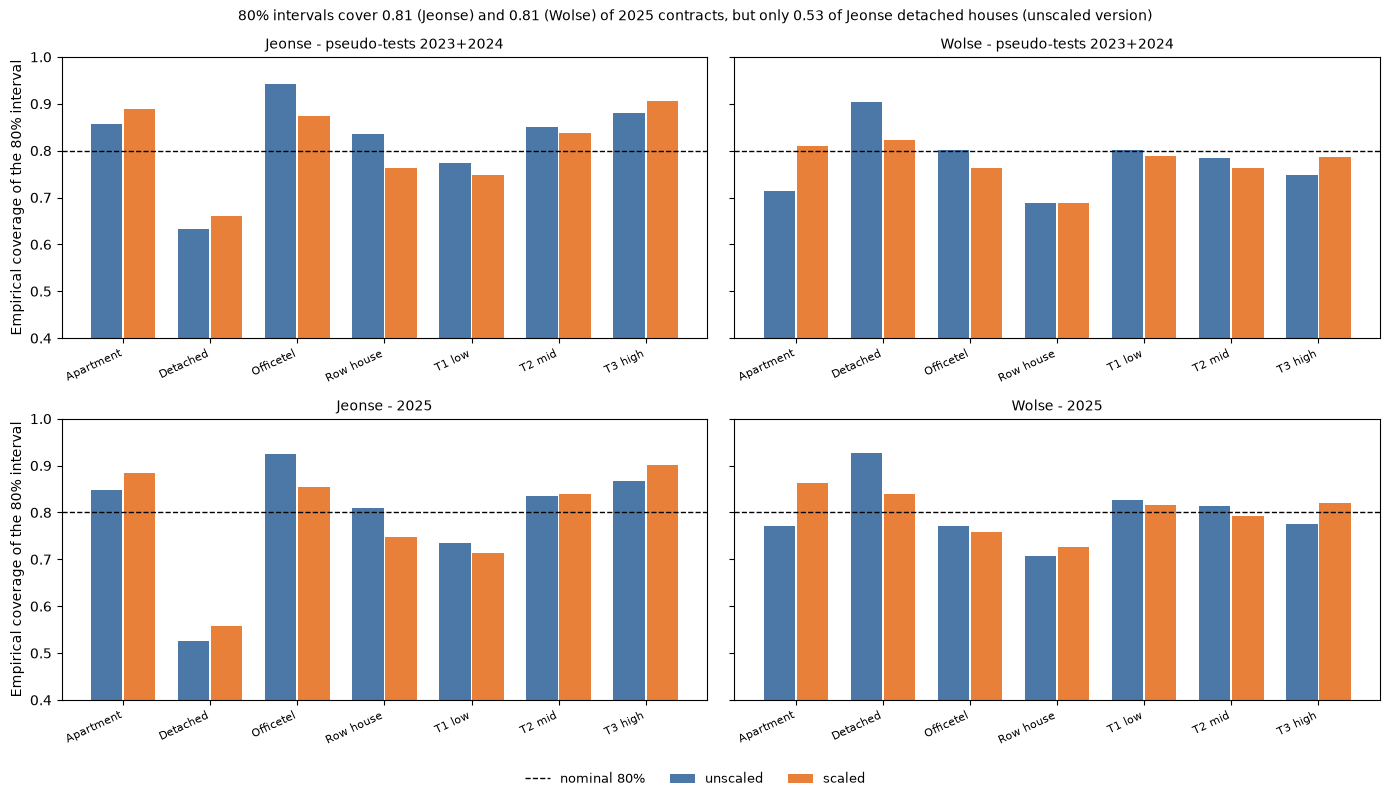

In [7]:
COLORS = {'unscaled': '#4c78a8', 'scaled': '#e8803a'}
g25 = {t: group_tables[(t, '2025')] for t in config.TRACKS}
worst = g25['jeonse'][(g25['jeonse']['nominal'] == 0.8) & (g25['jeonse']['version'] == 'unscaled')].nsmallest(1, 'coverage').iloc[0]
coverage_title = (f"80% intervals cover {overall.loc[('jeonse', '2025', 'unscaled', 0.8), 'coverage']:.2f} (Jeonse) and {overall.loc[('wolse', '2025', 'unscaled', 0.8), 'coverage']:.2f} (Wolse) "
                  f"of 2025 contracts, but only {worst['coverage']:.2f} of Jeonse {worst['group'].split(' / ')[0].lower()} houses (unscaled version)")
print(coverage_title)
fig, axes = plt.subplots(2, 2, figsize=(14, 8), sharey=True)
for r, label in enumerate(('pseudo-tests 2023+2024', '2025')):
    for c, track in enumerate(config.TRACKS):
        ax = axes[r, c]
        t = group_tables[(track, label)]
        t = t[(t['nominal'] == 0.8)]
        labels = list(dict.fromkeys(t['group']))
        x = np.arange(len(labels))
        for i, version in enumerate(('unscaled', 'scaled')):
            v = t[t['version'] == version].set_index('group').reindex(labels)
            ax.bar(x + (i - 0.5) * 0.38, v['coverage'], width=0.36, color=COLORS[version], label=version)
        ax.axhline(0.8, color='k', ls='--', lw=1, label='nominal 80%')
        ax.set_xticks(x); ax.set_xticklabels([s.replace(' / Multi-household house', '').replace(' / Villa (multi-unit)', '') for s in labels], rotation=25, ha='right', fontsize=8)
        ax.set_title(f'{track.capitalize()} - {label}', fontsize=10); ax.set_ylim(0.4, 1.0)
        if c == 0: ax.set_ylabel('Empirical coverage of the 80% interval')
handles, labels_ = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels_, loc='lower center', ncol=3, fontsize=9, frameon=False)
plt.suptitle(coverage_title, fontsize=10)
plt.tight_layout(rect=(0, 0.04, 1, 1)); plt.savefig(config.FIGURES_DIR / '12_coverage_by_group.png', dpi=130); plt.show()

**Interpretation.** The figure shows the 80% coverage by group against the dashed nominal line. The bars of the large groups (apartments, middle and high terciles) are close to the line, while the bars of Jeonse detached houses are far below it in the pseudo-tests and in 2025 (0.5582 and 0.5265 in 2025), and the low-price tercile also stays below nominal in Jeonse. The scaled and unscaled bars move in opposite directions in several groups, as the table shows.

Interval width follows the price level (80% interval, 2025, 10,000 KRW): Jeonse apartments 29,884 vs detached houses 8,013; Wolse 162 vs 83


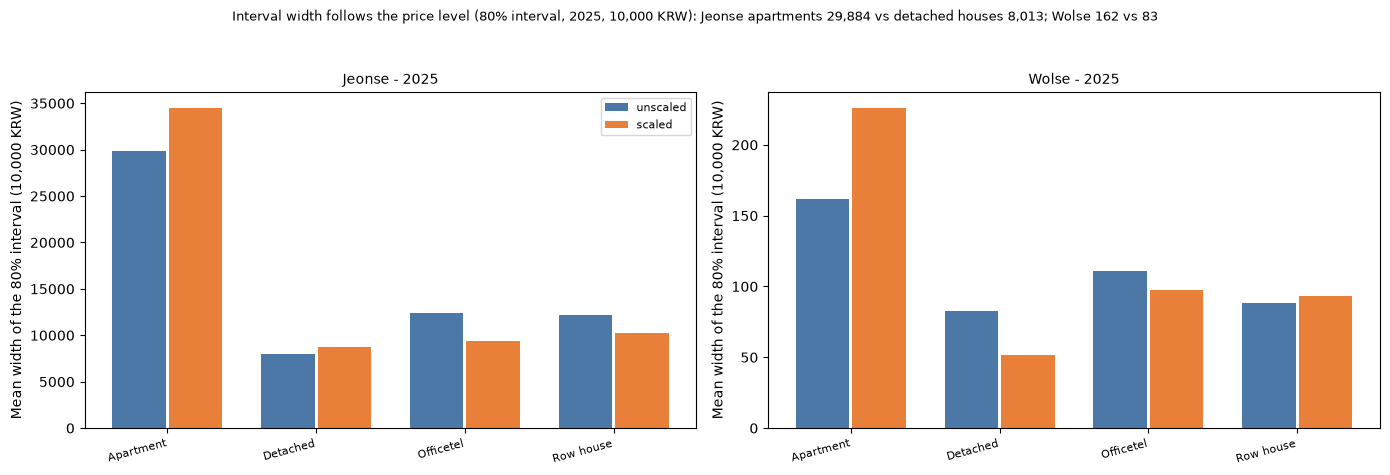

In [8]:
def mean_width(track, group):
    t = g25[track]
    return float(t[(t['nominal'] == 0.8) & (t['version'] == 'unscaled') & (t['group'] == group)]['mean_width'].iloc[0])
width_title = (f"Interval width follows the price level (80% interval, 2025, 10,000 KRW): Jeonse apartments {mean_width('jeonse', 'Apartment'):,.0f} vs detached houses "
               f"{mean_width('jeonse', 'Detached / Multi-household house'):,.0f}; Wolse {mean_width('wolse', 'Apartment'):,.0f} vs {mean_width('wolse', 'Detached / Multi-household house'):,.0f}")
print(width_title)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
for c, track in enumerate(config.TRACKS):
    ax = axes[c]
    t = group_tables[(track, '2025')]
    t = t[(t['nominal'] == 0.8) & (t['grouping'] == 'building type')]
    labels = list(dict.fromkeys(t['group'])); x = np.arange(len(labels))
    for i, version in enumerate(('unscaled', 'scaled')):
        v = t[t['version'] == version].set_index('group').reindex(labels)
        ax.bar(x + (i - 0.5) * 0.38, v['mean_width'], width=0.36, color=COLORS[version], label=version)
    ax.set_xticks(x); ax.set_xticklabels([s.replace(' / Multi-household house', '').replace(' / Villa (multi-unit)', '') for s in labels], rotation=15, ha='right', fontsize=8)
    ax.set_title(f'{track.capitalize()} - 2025', fontsize=10); ax.set_ylabel('Mean width of the 80% interval (10,000 KRW)')
    if c == 0: ax.legend(fontsize=8)
plt.suptitle(width_title, fontsize=9); plt.tight_layout(rect=(0, 0, 1, 0.94)); plt.savefig(config.FIGURES_DIR / '12_interval_width.png', dpi=130); plt.show()

**Interpretation.** The mean width of the 80% interval is largest for apartments in both tracks (Jeonse scaled 34,475.0481 and Wolse scaled 225.9346, in 10,000 KRW) and smallest for detached houses (Jeonse 8,726.4985, Wolse 51.8605): the width follows the price level, and the relative width is the quantity to compare across groups. The scaled version is wider for apartments and narrower for officetels and row houses in Jeonse.

## 6) Save the intervals under the model id `<chosen>_conformal`

In [9]:
# Version kept as the primary interval: the one whose coverage by building type and tercile is closer to nominal on the PSEUDO-TESTS (2025 does not choose).
gaps = {}
for scaled in (False, True):
    g = []
    for track in config.TRACKS:
        t = group_tables[(track, 'pseudo-tests 2023+2024')]
        sub = t[t['version'] == ('scaled' if scaled else 'unscaled')]
        g.append((sub['coverage'] - sub['nominal']).abs().mean())
    gaps['scaled' if scaled else 'unscaled'] = float(np.mean(g))
primary = min(gaps, key=gaps.get)
print('mean |coverage - nominal| over groups and levels on the pseudo-tests:', {k: round(v, 4) for k, v in gaps.items()}, '-> primary version:', primary)

for track in config.TRACKS:
    model_id = chosen[track]
    r = R[(track, '2025')]; cal = r['cal']; a = A[(track, '2025')]; ap = A[(track, 'pseudo-tests 2023+2024')]
    scaled = primary == 'scaled'
    meta = {'base_model': model_id, 'method': 'split conformal on log1p, absolute residuals, finite-sample quantile', 'version': primary,
            'calibration_window': f'{cal.start} to {cal.last}', 'calibration_rows': cal.n,
            'radius_log': {str(lv): cal.q_scaled[lv] if scaled else cal.q[lv] for lv in LEVELS},
            'radius_log_unscaled': {str(lv): cal.q[lv] for lv in LEVELS}, 'radius_log_scaled': {str(lv): cal.q_scaled[lv] for lv in LEVELS},
            'sigma_building_type': {str(k): v for k, v in cal.sigma.items()},
            'coverage_2025': {str(lv): coverage(a['y'], *a['iv'][scaled][lv])[0] for lv in LEVELS},
            'mean_width_2025': {str(lv): coverage(a['y'], *a['iv'][scaled][lv])[1] for lv in LEVELS},
            'coverage_pseudo_tests': {str(lv): coverage(ap['y'], *ap['iv'][scaled][lv])[0] for lv in LEVELS}}
    save_run(track, f'{model_id}_conformal', r['y'], r['pred'], meta=meta,
             context=data[track]['test'][['district_name', 'contract_date']])
    bounds = pd.read_parquet(config.PREDICTIONS_DIR / f'{track}__{model_id}_conformal.parquet')
    for lv in LEVELS:
        bounds[f'lower_{int(lv * 100)}'], bounds[f'upper_{int(lv * 100)}'] = a['iv'][scaled][lv]
    bounds.to_parquet(config.PREDICTIONS_DIR / f'{track}__{model_id}_conformal.parquet', index=False)
    print(f"{track}: saved {model_id}_conformal ({primary}); coverage 2025 80%/95%: " + ' / '.join(f"{meta['coverage_2025'][str(lv)]:.4f}" for lv in LEVELS)
          + f"; pseudo-tests: " + ' / '.join(f"{meta['coverage_pseudo_tests'][str(lv)]:.4f}" for lv in LEVELS))

mean |coverage - nominal| over groups and levels on the pseudo-tests: {'unscaled': 0.0474, 'scaled': 0.042} -> primary version: scaled
jeonse: saved hgb_detrended_ld_median_recal_conformal (scaled); coverage 2025 80%/95%: 0.8186 / 0.9595; pseudo-tests: 0.8302 / 0.9554
wolse: saved hgb_detrended_ld_median_conformal (scaled); coverage 2025 80%/95%: 0.8095 / 0.9542; pseudo-tests: 0.7794 / 0.9339


**Interpretation.** The version kept as primary is the one with the smaller mean absolute gap between coverage and nominal over groups and levels on the pseudo-tests (0.042 for the scaled version against 0.0474 for the unscaled one): the difference is small and the choice does not use 2025. The runs `hgb_detrended_ld_median_recal_conformal` (Jeonse) and `hgb_detrended_ld_median_conformal` (Wolse) hold the point prediction of the chosen model, and their meta holds the radii, the difficulty estimates, the calibration window and the coverage (2025: 0.8186 and 0.9595 in Jeonse, 0.8095 and 0.9542 in Wolse; pseudo-tests: 0.8302 and 0.9554, 0.7794 and 0.9339); the bounds of every 2025 contract are stored in the prediction file of each run.

## Summary

## Conclusion

- **Marginal coverage holds on 2025.** The conformal intervals of the chosen models cover 0.8186 / 0.9595 (Jeonse) and 0.8095 / 0.9542 (Wolse) at the 80% / 95% levels, close to nominal, with the primary (scaled) version.
- **It does not hold in every window.** The Wolse pseudo-test of 2024 covers only 0.7504 / 0.9277 (unscaled) because the error scale grew after the calibration window; the guarantee needs exchangeability between the calibration window and the evaluation year.
- **It does not hold by group.** Jeonse detached houses are covered only 0.5582 (scaled) at the 80% level in 2025, and the low-price tercile also under-covers; the building-type scaling does not give group-conditional coverage.
- **The intervals are wide,** especially in Wolse (median relative width 1.6647 of the prediction for the 80% unscaled interval), which agrees with the high WAPE.
- **Use.** The interval describes one contract around the model; it is not a forecast of the future price level (see the scenario tables of notebook 09).